Eugenio Hernández Aranda

756225

14/09/2026

# Tarea 2

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [4]:
k= 100
St= np.linspace(50,200)
from scipy.stats import norm

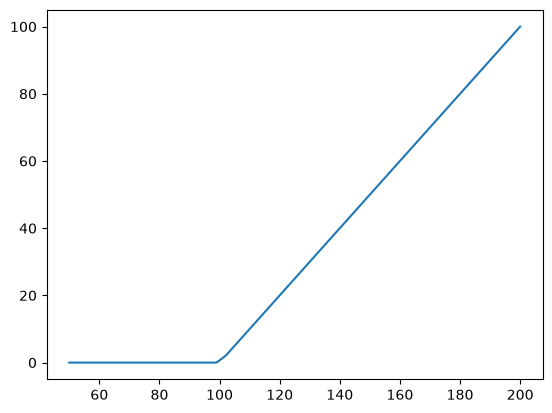

In [5]:
plt.plot(St,np.maximum(St-k, 0))

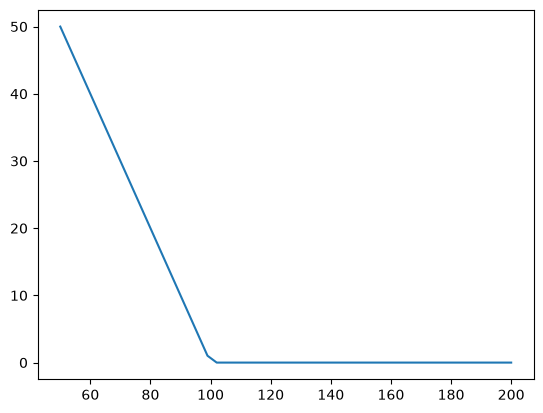

In [6]:
plt.plot(St,np.maximum(k-St, 0))

Asumiendo un $S(0)= 100, \ k=100, \ r=5\%, \sigma = 0.2, \ T=1, \ M=10000$

Simulación Monte Carlo

In [35]:
M = 10000
np.random.seed(42)
Z = np.random.normal(loc=0.0, scale=1.0, size=M)

S_T = s_0 * np.exp((r - 0.5 * sigma**2) * t + sigma * np.sqrt(t) * Z)

payoff_call = np.maximum(S_T - k, 0)

call_mc = np.exp(-r * t) * np.mean(payoff_call)



Comprando con la ecuación de black Scholes

In [8]:
from numpy import log
def d1(S_0, k, r, sigma, T):
    return (log(S_0/k)+(r+((sigma**2)/2))*T)/(sigma*np.sqrt(T))

def d2(d1, sigma, T):
    return d1-(sigma*np.sqrt(T))

def c(S_0, d1,d2, r, T):
    return S_0*norm.cdf(d1)-k*np.exp(-r*T)*norm.cdf(d2)

rd1= d1(s_0, k, r, sigma, t)
rd2= d2(rd1, sigma, t)
rc= c(s_0, rd1, rd2, r, t)
print(rc)

10.450583572185565


In [36]:
print(f"Call Monte Carlo: {call_mc:.4f}")
print(f"Call Black-Scholes: {rc:.4f}")

Call Monte Carlo: 10.4502
Call Black-Scholes: 10.4506


## Análisis de sensibilidad

Modificando el strike


In [9]:
t= 1
s_0=100
r=.05
sigma=.2
W_t= 0
k= 100

k=70
k_list= []
rc_k_list=[]
for i in range(5):
    k=k+10
    rd1= d1(s_0, k, r, sigma, t)
    rd2= d2(rd1, sigma, t)
    rc_k= c(s_0, rd1, rd2, r, t)
    k_list.append([k])
    rc_k_list.append(rc_k)
    print(rc_k)
    print(k)

print(rc_k_list)

24.58883544392775
80
16.699448408416004
90
10.450583572185565
100
6.040088129724239
110
3.2474774165608125
120
[np.float64(24.58883544392775), np.float64(16.699448408416004), np.float64(10.450583572185565), np.float64(6.040088129724239), np.float64(3.2474774165608125)]


Modificando el precio del activo

In [10]:
t= 1
s_0=100
r=.05
sigma=.2
W_t= 0
k= 100

s_0= 70

s0_list= []
rc_s0_list=[]
for i in range(5):
    s_0=s_0+10
    rd1= d1(s_0, k, r, sigma, t)
    rd2= d2(rd1, sigma, t)
    rc_s0= c(s_0, rd1, rd2, r, t)
    s0_list.append([s_0])
    rc_s0_list.append(rc_s0)
    print(rc_s0)
    print(s_0)

1.8594195728121825
80
5.091222078817552
90
10.450583572185565
100
17.66295374059044
110
26.169043946847296
120


Modificando la volatilidad

In [11]:
t= 1
s_0=100
r=.05
sigma=.2
W_t= 0
k= 100

sigma= 0
sigma_list= []
rc_sigma_list=[]
for i in range(5):
    sigma=sigma+.10
    rd1= d1(s_0, k, r, sigma, t)
    rd2= d2(rd1, sigma, t)
    rc_sigma= c(s_0, rd1, rd2, r, t)
    sigma_list.append([sigma])
    rc_sigma_list.append(rc_sigma)

    print(rc_sigma)
    print(sigma)

6.804957708822144
0.1
10.450583572185565
0.2
14.231254785985826
0.30000000000000004
18.02295145021668
0.4
21.79260421286685
0.5


Modificando el tiempo


In [12]:
t= 1
s_0=100
r=.05
sigma=.2
W_t= 0
k= 100

t=0
t_list= []
rc_t_list=[]
for i in range(8):
    t=t+.25
    rd1= d1(s_0, k, r, sigma, t)
    rd2= d2(rd1, sigma, t)
    rc_t= c(s_0, rd1, rd2, r, t)
    t_list.append([t])
    rc_t_list.append(rc_t)
    print(rc_t)
    print(t)

4.614997129602855
0.25
6.888728577680624
0.5
8.772268259756942
0.75
10.450583572185565
1.0
11.995238476119916
1.25
13.442904812585333
1.5
14.815356681060287
1.75
16.126779724978633
2.0


Modificiando el rendimiento

In [13]:
t= 1
s_0=100
r=.05
sigma=.2
W_t= 0
k= 100

r=0
r_list= []
rc_r_list=[]
for i in range(4):
    r=r+.05
    rd1= d1(s_0, k, r, sigma, t)
    rd2= d2(rd1, sigma, t)
    rc_r= c(s_0, rd1, rd2, r, t)
    r_list.append([r])
    rc_r_list.append(rc_r)
    print(rc_r)
    print(f"{r:.2f}")

10.450583572185565
0.05
13.269676584660893
0.10
16.355968471303683
0.15
19.62988710124155
0.20


In [ ]:
# t= np.linspace(.25,2, 10000)
# s_0=np.linspace(80,120,10000)
# r=np.linspace(.05,.4,10000)
# sigma=np.linspace(.05, .4,10000)
# k=100

In [15]:
# print(t)

# Put


Simulación Monte Carlo

In [ ]:
payoff_put = np.maximum(k - S_T, 0)
put_mc = np.exp(-r * t) * np.mean(payoff_put)


In [17]:
t = 1
s_0 = 100
r = .05
sigma = .2
W_t = 0
k = 100

Comparando con black Scholes

In [18]:
from numpy import log
def d1(S_0, k, r, sigma, T):
    return (log(S_0/k)+(r+((sigma**2)/2))*T)/(sigma*np.sqrt(T))

def d2(d1, sigma, T):
    return d1-(sigma*np.sqrt(T))

def p(S_0, d1, d2, r, T):
    return k*np.exp(-r*T)*norm.cdf(-d2) - S_0*norm.cdf(-d1)

rd1 = d1(s_0, k, r, sigma, t)
rd2 = d2(rd1, sigma, t)
rp = p(s_0, rd1, rd2, r, t)
print(rp)

5.573526022256971


In [38]:
print(f"Put Monte Carlo:  {put_mc:.4f}")
print(f"Put Black-Scholes:  {rp:.4f}")

Put Monte Carlo:  5.6017
Put Black-Scholes:  5.5735


Modificando el strike

In [19]:
t= 1
s_0=100
r=.05
sigma=.2
W_t= 0
k= 100

k=70

k_list= []
rp_k_list=[]
for i in range(5):
    k=k+10
    rd1= d1(s_0, k, r, sigma, t)
    rd2= d2(rd1, sigma, t)
    rp_k= p(s_0, rd1, rd2, r, t)
    k_list.append([k])
    rp_k_list.append(rp_k)
    print(rp_k)
    print(k)



0.6871894039848714
80
2.3100966134802654
90
5.573526022256971
100
10.675324824802793
110
17.3950083566465
120


Modificando el precio del activo

In [20]:
t= 1
s_0=100
r=.05
sigma=.2
W_t= 0
k= 100

s_0= 70
s0_list= []
rp_s0_list=[]
for i in range(5):
    s_0=s_0+10
    rd1= d1(s_0, k, r, sigma, t)
    rd2= d2(rd1, sigma, t)
    rp_s0= p(s_0, rd1, rd2, r, t)
    s0_list.append([s_0])
    rp_s0_list.append(rp_s0)
    print(rp_s0)
    print(s_0)

16.982362022883592
80
10.214164528888958
90
5.573526022256971
100
2.785896190661841
110
1.2919863969187073
120


Modificando la volatilidad

In [21]:
t= 1
s_0=100
r=.05
sigma=.2
W_t= 0
k= 100

sigma= .0
sigma_list= []
rp_sigma_list=[]
for i in range(5):
    sigma=sigma+.10
    rd1= d1(s_0, k, r, sigma, t)
    rd2= d2(rd1, sigma, t)
    rp_sigma= p(s_0, rd1, rd2, r, t)
    sigma_list.append([sigma])
    rp_sigma_list.append(rp_sigma)
    print(rp_sigma)
    print(sigma)

1.92790015889355
0.1
5.573526022256971
0.2
9.354197236057232
0.30000000000000004
13.145893900288087
0.4
16.915546662938254
0.5


Modificando el tiempo

In [22]:
t= 1
s_0=100
r=.05
sigma=.2
W_t= 0
k= 100

t= .0
t_list= []
rp_t_list=[]
for i in range(8):
    t=t+.25
    rd1= d1(s_0, k, r, sigma, t)
    rd2= d2(rd1, sigma, t)
    rp_t= p(s_0, rd1, rd2, r, t)
    t_list.append([t])
    rp_t_list.append(rp_t)
    print(rp_t)
    print(t)

3.372777178991008
0.25
4.41971978051388
0.5
5.091710031839128
0.75
5.573526022256971
1.0
5.936544757467502
1.25
6.217253445440619
1.5
6.437243846148043
1.75
6.610521528574566
2.0


Modificando el rendimiento

In [23]:
t= 1
s_0=100
r=.05
sigma=.2
W_t= 0
k= 100

r= .0
r_list= []
rp_r_list=[]
for i in range(4):
    r=r+.05
    rd1= d1(s_0, k, r, sigma, t)
    rd2= d2(rd1, sigma, t)
    rp_r= p(s_0, rd1, rd2, r, t)
    r_list.append([r])
    rp_r_list.append(rp_r)
    print(rp_r)
    print(r)

5.573526022256971
0.05
3.753418388256833
0.1
2.4267661138094674
0.15000000000000002
1.5029624090397462
0.2


# Visualización

## Strike vs Premium

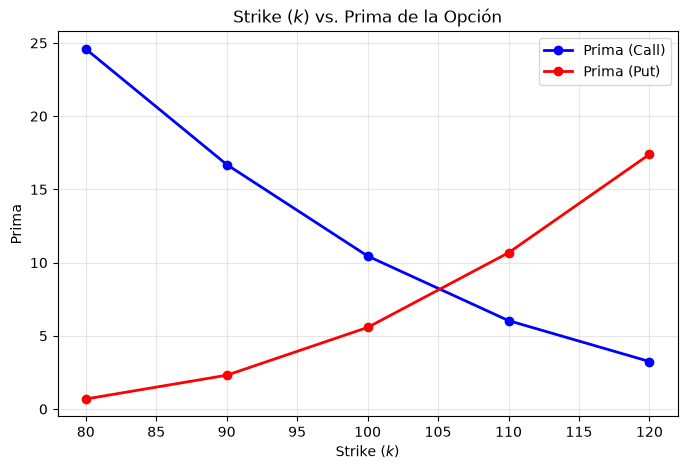

In [24]:
plt.figure(figsize=(8, 5))
plt.plot(k_list, rc_k_list, marker='o', color='blue', linewidth=2, label='Prima (Call)')
plt.plot(k_list, rp_k_list,marker='o', color='r', linewidth=2, label='Prima (Put)')

plt.title('Strike ($k$) vs. Prima de la Opción')
plt.xlabel('Strike ($k$)')
plt.ylabel('Prima')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

## Precio de la opción vs precio del activo



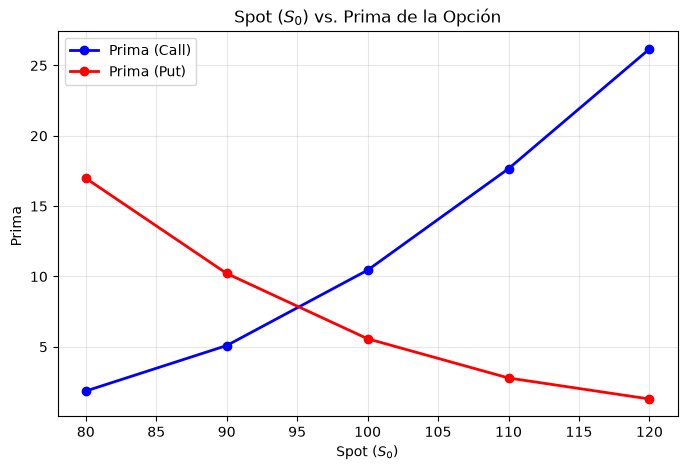

In [25]:
plt.figure(figsize=(8, 5))
plt.plot(s0_list, rc_s0_list, marker='o', color='blue', linewidth=2, label='Prima (Call)')
plt.plot(s0_list, rp_s0_list,marker='o', color='r', linewidth=2, label='Prima (Put)')

plt.title('Spot ($S_0$) vs. Prima de la Opción')
plt.xlabel('Spot ($S_0$)')
plt.ylabel('Prima ')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

## Precio de la opción vs volatilidad


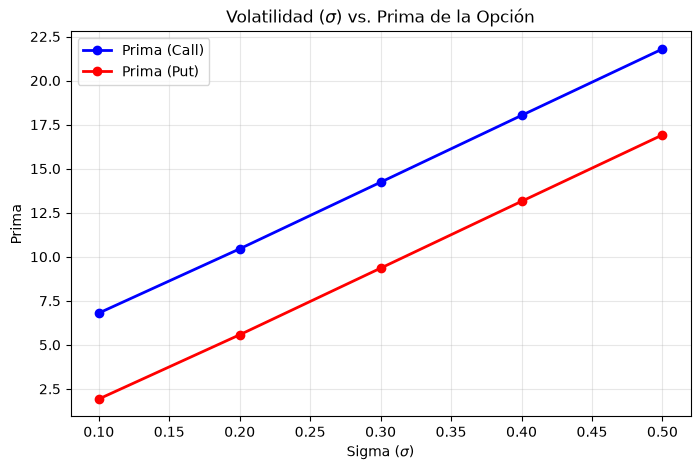

In [26]:
plt.figure(figsize=(8, 5))
plt.plot(sigma_list, rc_sigma_list, marker='o', color='blue', linewidth=2, label='Prima (Call)')
plt.plot(sigma_list, rp_sigma_list,marker='o', color='r', linewidth=2, label='Prima (Put)')

plt.title('Volatilidad ($\sigma$) vs. Prima de la Opción')
plt.xlabel('Sigma ($\sigma$)')
plt.ylabel('Prima')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

## Precio de la opción vs tiempo


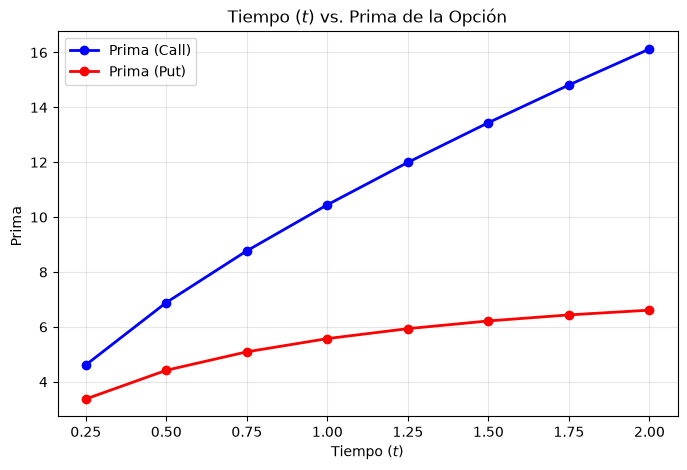

In [27]:
plt.figure(figsize=(8, 5))
plt.plot(t_list, rc_t_list, marker='o', color='blue', linewidth=2, label='Prima (Call)')
plt.plot(t_list, rp_t_list,marker='o', color='r', linewidth=2, label='Prima (Put)')

plt.title('Tiempo ($t$) vs. Prima de la Opción')
plt.xlabel('Tiempo ($t$)')
plt.ylabel('Prima ')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

## Precio de la opción vs rendimiento


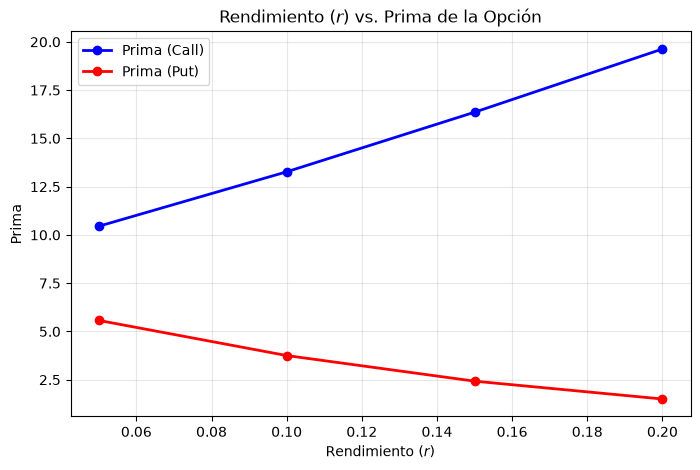

In [28]:
plt.figure(figsize=(8, 5))
plt.plot(r_list, rc_r_list, marker='o', color='blue', linewidth=2, label='Prima (Call)')
plt.plot(r_list, rp_r_list,marker='o', color='r', linewidth=2, label='Prima (Put)')

plt.title('Rendimiento ($r$) vs. Prima de la Opción')
plt.xlabel('Rendimiento ($r$)')
plt.ylabel('Prima')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

# Insights


## Precio del activo

¿Por qué una call aumenta cuando aumenta el precio de la acción?
- Porque cuando el precio de una acción sube su valor esperado aumenta, lo que hace que el precio de la prima también se eleve

¿Por qué una put se comporta de manera distinta?
- Como con el put otorga el derecho de vender a un precio fijo de strke, un aumento en el precio de la acción solo te aleja de la zona de ganancia ya que la probabilidad de ejercer con un beneficio disminuye 

## Volatilidad

¿Por qué una mayor incertidumbre aumenta o disminuye el valor de la opción?
- Cómo el comprador solo asume el riesgo de no ejercer la opción y aún así paga la prima, entre más volátil es un activo, más posibilidades tiene de ganar más dinero sin asumir ningún tipo de riesgo adicional, lo que hace que aumente el valor de la opción

## Tiempo

¿Siempre es deseable tener más tiempo?
- En el caso de las calls sí, ya que el valor sigue aumentando, en el caso de las puts se termina estancando con el tiempo
¿Para quién resulta favorable?
- Para el comprador ya que es más probable que la acción se mueva a su favor
## Strike

¿Cómo modifica el strike la probabilidad de termina in-the-money?
- Justo el strike es lo que define si una opción termina in-the-money o no, por ejemplo, un call in-the-money se ve así: $S_t \gt k$, lo que significa que entre más alto este k con respecto a $S_0$, más difícil es que la opción termine in-the-money, y para el put es lo mismo pero al revés

## Definir in-the-money
- Es cuando una opción tiene más valor cuando se ejerce que el precio del mercado

# Parte 4. Comparación con el mercado

Si fueras un inversionista, ¿cuál parámetro consideras más importante monitorear? ¿Por qué? Justifica usando tus resultados
- Si yo fuera inversionista el parámetro más importante de monitorear para mí sería la volatilidad, ya que es la que me garantiza mayores probabilidades de ganancia sin ningún tipo de riesgo añadido, además de que me da la flexibilidad de que esto pasa tanto para los calls como para los puts, como se puede observar en las gráficas anteriores